# Constraint Generation: Fixing the Sampling Approximation

Robot beacon localization project — Step 4. Reuses `map_gen.py`, `visibility.py`, `solvers.py`.

## The problem: the previous step's "optimal solution" is actually wrong

Step 3's ILP found a "provably optimal" layout on the `RES=4` sample points. But the robot can stand **anywhere** in the free space,
not just on those 1760 sample points. Writing the constraints only at the sample points means:

> The solver is free to return a layout that satisfies every sample point yet leaves blind spots **between** the sample points where fewer than 3 beacons are visible.

This notebook first confirms experimentally that this really happens, then fixes it with **constraint generation**:
solve on a coarse grid, verify on a fine grid, add the violating points back to the model as new constraints, and iterate until there are no violations.

This is a standard technique in the solver world (also called lazy constraints / cutting planes):
**there is no need to write down all the constraints up front; add them only when they are violated**.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from map_gen import make_map
from visibility import sample_points, visibility_matrix, wall_arrays
from solvers import greedy_cover, ilp_cover, verify, K_DEFAULT as K

GRID_W, GRID_H, TARGET, HOLES, SEED = 16, 12, 120, 10, 42
RES_SOLVE = 4     # coarse sampling used for solving
RES_CHECK = 16    # fine sampling used for verification (256 points per cell)

cells, segments, corners, mids = make_map(GRID_W, GRID_H, TARGET, HOLES, SEED)
beacons = corners + mids
W1, W2 = wall_arrays(segments)

P_solve = sample_points(cells, RES_SOLVE)
P_check = sample_points(cells, RES_CHECK)
print(f'candidates      : {len(beacons)}')
print(f'coarse grid     : {len(P_solve):6d} points  (RES={RES_SOLVE})')
print(f'fine  grid      : {len(P_check):6d} points  (RES={RES_CHECK})  '
      f'— {len(P_check) // len(P_solve)}x denser')

candidates      : 144
coarse grid     :   1760 points  (RES=4)
fine  grid      :  28160 points  (RES=16)  — 16x denser


## 1. Confirming the problem exists

Find the optimal solution on the coarse grid, then re-check it on the fine grid. If the sampling approximation were safe, the re-check would find zero violations.

In [2]:
V_solve = visibility_matrix(beacons, P_solve, cells, W1, W2)
sol0, status0 = ilp_cover(V_solve, hint=greedy_cover(V_solve))
ok0, _ = verify(V_solve, sol0)
print(f'Solved on the coarse grid: {len(sol0)} beacons, status={status0}, all coarse points satisfied={ok0}')

# only the selected beacons need checking — much cheaper than the full candidate matrix
V_chk = visibility_matrix([beacons[j] for j in sol0], P_check, cells, W1, W2)
counts0 = V_chk.sum(axis=1)
bad0 = np.where(counts0 < K)[0]
print(f'Re-checked on the fine grid: {len(bad0)} points cannot see {K} beacons '
      f'({100 * len(bad0) / len(P_check):.3f}%), the worst point sees only {counts0.min()}')
print('\n=> The sampling approximation is unsafe: the robot cannot localize at these positions, and the coarse grid never noticed.')

Solved on the coarse grid: 24 beacons, status=OPTIMAL, all coarse points satisfied=True
Re-checked on the fine grid: 2 points cannot see 3 beacons (0.007%), the worst point sees only 2

=> The sampling approximation is unsafe: the robot cannot localize at these positions, and the coarse grid never noticed.


### Where the blind spots are

Plot the violating points. They usually hug a wall surface or hide near a narrow reflex corner — where visibility changes most abruptly,
and the coarse grid's sample points happen to "step over" these thin regions.

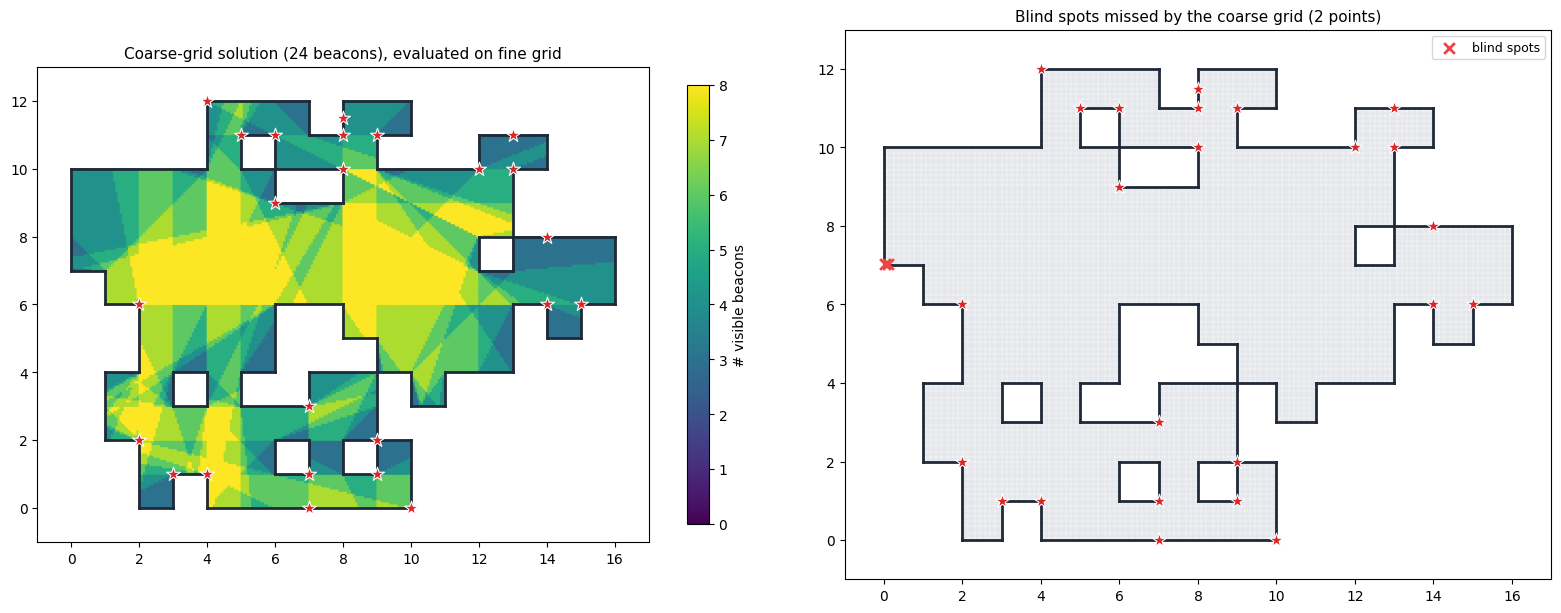

In [3]:
def draw_map(ax, cells, segments):
    for (x, y) in cells:
        ax.add_patch(Rectangle((x, y), 1, 1, facecolor='#f8fafc', edgecolor='none'))
    for (x1, y1), (x2, y2) in segments:
        ax.plot([x1, x2], [y1, y2], color='#1f2937', linewidth=2, zorder=3)
    xs = [x for x, _ in cells]; ys = [y for _, y in cells]
    ax.set_xlim(min(xs) - 1, max(xs) + 2)
    ax.set_ylim(min(ys) - 1, max(ys) + 2)
    ax.set_aspect('equal')


fig, axes = plt.subplots(1, 2, figsize=(16, 6))

draw_map(axes[0], cells, segments)
sc = axes[0].scatter(P_check[:, 0], P_check[:, 1], c=counts0, s=2,
                     cmap='viridis', vmin=0, vmax=8, zorder=2)
plt.colorbar(sc, ax=axes[0], shrink=0.8, label='# visible beacons')
cb = np.array([beacons[j] for j in sol0], dtype=float)
axes[0].scatter(cb[:, 0], cb[:, 1], s=110, marker='*', color='#dc2626',
                edgecolor='white', linewidth=0.8, zorder=4)
axes[0].set_title(f'Coarse-grid solution ({len(sol0)} beacons), evaluated on fine grid',
                  fontsize=11)

draw_map(axes[1], cells, segments)
axes[1].scatter(P_check[:, 0], P_check[:, 1], s=1, color='#e5e7eb', zorder=2)
if len(bad0):
    axes[1].scatter(P_check[bad0, 0], P_check[bad0, 1], s=60, color='#ef4444',
                    marker='x', linewidth=2, zorder=5, label='blind spots')
    axes[1].legend(loc='upper right', fontsize=9)
axes[1].scatter(cb[:, 0], cb[:, 1], s=110, marker='*', color='#dc2626',
                edgecolor='white', linewidth=0.8, zorder=4)
axes[1].set_title(f'Blind spots missed by the coarse grid ({len(bad0)} points)',
                  fontsize=11)
plt.tight_layout()
plt.show()

## 2. Constraint generation

The naive fix is to model directly on the fine grid, but that means 28160 constraints and building a 28160×144 visibility matrix —
a cost that grows with the square of the resolution (see the measurements in Section 4).

The idea of constraint generation: **the constraints of the vast majority of fine-grid points are redundant** (they are satisfied as a side effect of nearby points' constraints),
and only a handful of "troublemaker" points actually matter. So:

1. Use the coarse grid as the initial **active set** $A$
2. Solve the ILP to optimality on $A$
3. Verify that solution on the **fine grid** (only the selected beacons are evaluated, which is cheap)
4. No violations → done; violations → add the violating points to $A$ (computing full-candidate visibility only for them) and go back to step 2

Each round $A$ grows only by the violating points — a few to about a hundred — while solution quality is judged by the fine-grid standard.

**Why the result is optimal.** `sample_points` places points at sub-cell centres, so the coarse and fine grids **do not overlap**: the `RES=4` offsets (1/8, 3/8, …)
are not among the `RES=16` offsets (1/32, 3/32, …). The active set $A$ is therefore a subset of the **union** $P_{\text{coarse}} \cup P_{\text{fine}}$, not of the fine grid,
and **the optimal value on $A$ is a lower bound on the optimum over that union**. As soon as a round's solution has zero violations on the fine grid, it satisfies
the whole union (the coarse points are in $A$ from the start) and attains the bound — so it is the **optimal solution for the coarse and fine points together**.
That is a slightly stricter requirement than the fine grid alone (more points must be covered), so the answer can only err on the safe side; and it is still a
lower bound on the true minimum for this candidate set, because the robot's real requirement covers every point of free space.

In [4]:
def constraint_generation(beacons, cells, W1, W2, P_init, P_check,
                          k=K, max_iter=20, verbose=True):
    """Constraint generation: start from P_init and iterate until the solution has zero violations on P_check.

    Returns (selected beacon indices, list of iteration records)
    """
    A = P_init.copy()
    V_A = visibility_matrix(beacons, A, cells, W1, W2)
    log = []
    for it in range(1, max_iter + 1):
        sol, status = ilp_cover(V_A, k=k, hint=greedy_cover(V_A, k))
        # verify with the selected beacons only — the column count drops from |candidates| to |sol|
        V_sel = visibility_matrix([beacons[j] for j in sol], P_check, cells, W1, W2)
        bad = np.where(V_sel.sum(axis=1) < k)[0]
        log.append({'iter': it, 'active': len(A), 'n_beacons': len(sol),
                    'status': status, 'violations': len(bad)})
        if verbose:
            print(f'  iter {it}: |A|={len(A):6d}  ILP={len(sol):3d} ({status})  '
                  f'fine-grid violations={len(bad)}')
        if len(bad) == 0:
            return sol, log
        # compute full-candidate visibility only for the violating points and append them to the active set
        P_bad = P_check[bad]
        V_A = np.vstack([V_A, visibility_matrix(beacons, P_bad, cells, W1, W2)])
        A = np.vstack([A, P_bad])
    raise RuntimeError('did not converge within max_iter')


print('Constraint generation:')
t0 = time.time()
sol_cg, log_cg = constraint_generation(beacons, cells, W1, W2, P_solve, P_check)
t_cg = time.time() - t0
print(f'\nConverged: {len(sol_cg)} beacons, {len(log_cg)} iterations, {t_cg:.1f}s')
print(f'Change vs. the coarse-grid solution ({len(sol0)}): {len(sol_cg) - len(sol0):+d}')

Constraint generation:
  iter 1: |A|=  1760  ILP= 24 (OPTIMAL)  fine-grid violations=2
  iter 2: |A|=  1762  ILP= 24 (OPTIMAL)  fine-grid violations=0

Converged: 24 beacons, 2 iterations, 2.9s
Change vs. the coarse-grid solution (24): +0


## 3. Before vs. after the fix

Left: blind spots of the coarse-grid solution. Right: the solution after constraint generation, $\ge 3$ everywhere on the fine grid.

Final layout on the fine grid: minimum visible beacons 3, violating points 0


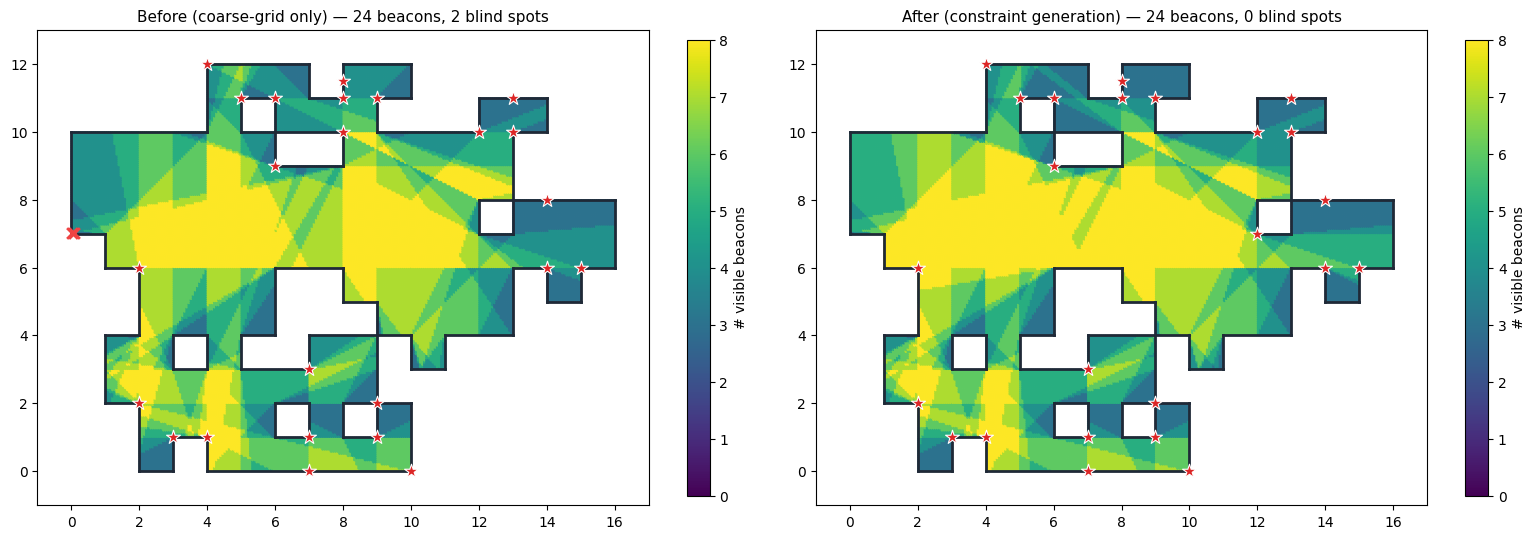

In [5]:
V_cg = visibility_matrix([beacons[j] for j in sol_cg], P_check, cells, W1, W2)
counts_cg = V_cg.sum(axis=1)
print(f'Final layout on the fine grid: minimum visible beacons {counts_cg.min()}, '
      f'violating points {int((counts_cg < K).sum())}')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, cnts, sel, name in [(axes[0], counts0, sol0, 'Before (coarse-grid only)'),
                            (axes[1], counts_cg, sol_cg, 'After (constraint generation)')]:
    draw_map(ax, cells, segments)
    sc = ax.scatter(P_check[:, 0], P_check[:, 1], c=cnts, s=2, cmap='viridis',
                    vmin=0, vmax=8, zorder=2)
    plt.colorbar(sc, ax=ax, shrink=0.8, label='# visible beacons')
    bad = np.where(cnts < K)[0]
    if len(bad):
        ax.scatter(P_check[bad, 0], P_check[bad, 1], s=60, color='#ef4444',
                   marker='x', linewidth=2, zorder=5)
    cbs = np.array([beacons[j] for j in sel], dtype=float)
    ax.scatter(cbs[:, 0], cbs[:, 1], s=110, marker='*', color='#dc2626',
               edgecolor='white', linewidth=0.8, zorder=4)
    ax.set_title(f'{name} — {len(sel)} beacons, {len(bad)} blind spots', fontsize=11)
plt.tight_layout()
plt.show()

## 4. Cost comparison: constraint generation vs. modeling the fine grid directly

Strictly, the two solve slightly different problems — the naive model covers only the fine grid, constraint generation the coarse and fine points
together (Section 2), so it can never return fewer beacons than the naive model — and here they give the same answer.
Their costs, however, differ markedly — and the gap widens as the resolution increases.
The bottleneck is **building the visibility matrix**: the naive approach computes the full $|P_{\text{fine}}|\times|B|$ matrix,
while constraint generation computes only $|P_{\text{fine}}|\times|\text{selected beacons}|$ (verification) plus the full rows of a handful of violating points.

In [6]:
t0 = time.time()
V_full = visibility_matrix(beacons, P_check, cells, W1, W2)
t_build = time.time() - t0
t0 = time.time()
sol_naive, st_naive = ilp_cover(V_full, hint=greedy_cover(V_full))
t_solve = time.time() - t0

print(f'Naive (fine grid directly): {len(sol_naive)} beacons ({st_naive})')
print(f'  matrix build {t_build:5.1f}s + ILP solve {t_solve:5.1f}s = {t_build + t_solve:5.1f}s')
print(f'  matrix size {V_full.shape}')
print(f'\nConstraint generation: {len(sol_cg)} beacons')
print(f'  total time {t_cg:5.1f}s, final active set only {log_cg[-1]["active"]} points '
      f'({100 * log_cg[-1]["active"] / len(P_check):.1f}% of the fine grid)')
print(f'\nSpeedup: {(t_build + t_solve) / t_cg:.1f}x, same answer: {len(sol_cg) == len(sol_naive)}')

Naive (fine grid directly): 24 beacons (OPTIMAL)
  matrix build   6.6s + ILP solve   1.4s =   7.9s
  matrix size (28160, 144)

Constraint generation: 24 beacons
  total time   2.9s, final active set only 1762 points (6.3% of the fine grid)

Speedup: 2.8x, same answer: True


## 5. Multi-map validation: how wrong is the coarse grid, really

Across several random maps, compare the "coarse-grid answer" with the "correct answer after constraint generation".

This is the most important table in this notebook — it answers: how many of the "optimal solutions" from Step 3 are actually untrustworthy?

In [7]:
rows = []
print(f'{"seed":>5} {"coarse":>9} {"1st blind":>9} {"iters":>6} {"correct":>8} {"under":>6}')
print('-' * 52)
for seed in range(6):
    c, s, co, mi = make_map(GRID_W, GRID_H, TARGET, HOLES, seed)
    B = co + mi
    w1, w2 = wall_arrays(s)
    Ps, Pc = sample_points(c, RES_SOLVE), sample_points(c, RES_CHECK)
    sol, log = constraint_generation(B, c, w1, w2, Ps, Pc, verbose=False)
    r = {'seed': seed, 'coarse': log[0]['n_beacons'], 'first_bad': log[0]['violations'],
         'iters': len(log), 'final': len(sol)}
    r['under'] = r['final'] - r['coarse']
    rows.append(r)
    print(f'{r["seed"]:>5} {r["coarse"]:>9} {r["first_bad"]:>9} {r["iters"]:>6} '
          f'{r["final"]:>8} {r["under"]:>+6}')
print('-' * 52)
under = np.array([r['under'] for r in rows])
print(f'On {int((under > 0).sum())}/{len(under)} maps the coarse grid gave too few beacons, '
      f'underestimating by {under.mean():.1f} on average')

 seed    coarse 1st blind  iters  correct  under
----------------------------------------------------
    0        21        22      3       22     +1
    1        24        45      2       25     +1
    2        27        40      4       28     +1
    3        24       106      3       26     +2
    4        18        60      4       21     +3
    5        23         0      1       23     +0
----------------------------------------------------
On 5/6 maps the coarse grid gave too few beacons, underestimating by 1.3 on average


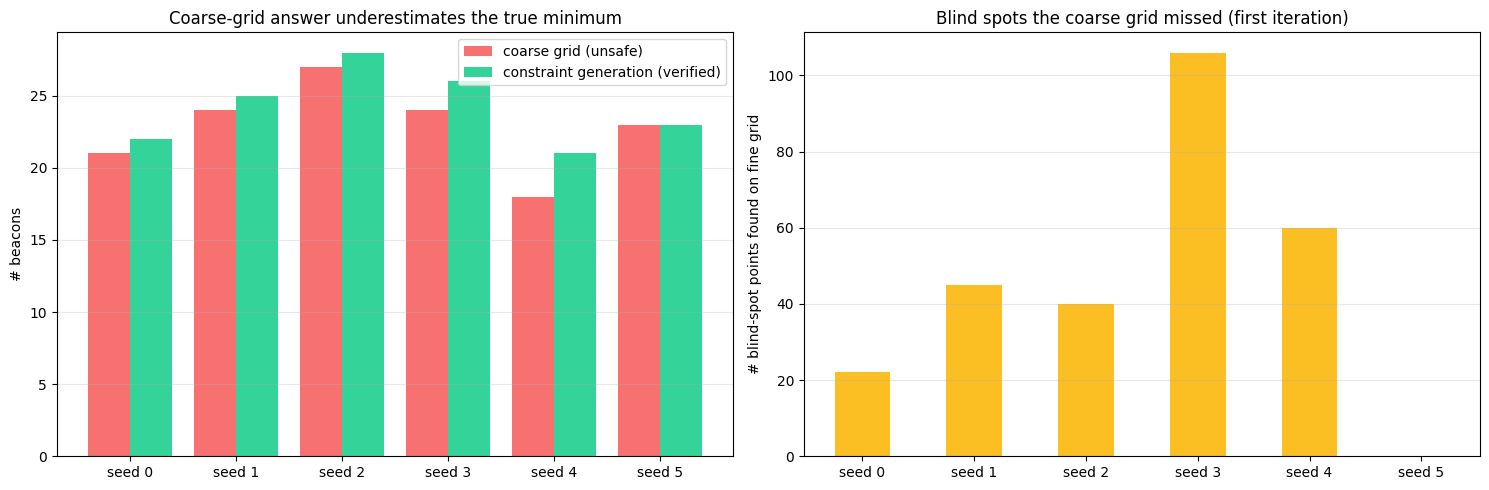

In [8]:
seeds = [r['seed'] for r in rows]
coarse = [r['coarse'] for r in rows]
final = [r['final'] for r in rows]
xs = np.arange(len(seeds))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(xs - 0.2, coarse, 0.4, label='coarse grid (unsafe)', color='#f87171')
axes[0].bar(xs + 0.2, final, 0.4, label='constraint generation (verified)',
            color='#34d399')
axes[0].set_xticks(xs); axes[0].set_xticklabels([f'seed {s}' for s in seeds])
axes[0].set_ylabel('# beacons'); axes[0].legend()
axes[0].set_title('Coarse-grid answer underestimates the true minimum')
axes[0].grid(alpha=0.3, axis='y')

axes[1].bar(xs, [r['first_bad'] for r in rows], 0.5, color='#fbbf24')
axes[1].set_xticks(xs); axes[1].set_xticklabels([f'seed {s}' for s in seeds])
axes[1].set_ylabel('# blind-spot points found on fine grid')
axes[1].set_title('Blind spots the coarse grid missed (first iteration)')
axes[1].grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

## Summary

**Core finding**: solving directly on the coarse grid **systematically underestimates** the number of beacons needed — by 1–3 on most random maps,
and the corresponding layouts leave blind spots in the real continuous space. Strictly speaking, Step 3's "provably optimal" conclusions hold only at the sample points.

**Constraint generation** fixes this at a small cost: the active set grows by only tens to about a hundred points (the fine grid has 28160), it converges within
a few iterations, and on the main map it is about 3× faster than modeling the fine grid directly, with the advantage growing at higher resolution.
The resulting solutions are **verified point by point** on the fine grid and are provably optimal for the coarse and fine sample points together (Section 2).

**The remaining gap (to be honest)**: this is still finite sampling. Zero violations at `RES=16` does not mean zero violations everywhere in continuous space —
it only pushes the chance of a missed blind spot lower. A truly rigorous guarantee needs a **visibility decomposition**:
cut the free space along all critical lines of sight (lines through a beacon and a wall corner),
so that the "set of visible beacons" is constant within each resulting region, and finitely many regions then represent infinitely many points exactly.
The constraints are then finite and **complete**, and only then is the ILP optimum the true optimum in the continuous sense.

The good news: the constraint-generation framework can take this upgrade **without modification** — just replace "fine-grid verification"
with "exact verification on the decomposed regions", and the loop logic stays as it is.